Episode 1: 8.0
Episode 2: 10.0
Episode 3: 67.0
Episode 4: 66.0
Episode 5: 143.0
Episode 6: 19.0
Episode 7: 10.0
Episode 8: 500.0
Episode 9: 9.0
Episode 10: 9.0
Episode 11: 18.0
Episode 12: 42.0
Episode 13: 8.0
Episode 14: 75.0
Episode 15: 10.0
Episode 16: 9.0
Episode 17: 11.0
Episode 18: 9.0
Episode 19: 9.0
Episode 20: 86.0
Episode 21: 123.0
Episode 22: 40.0
Episode 23: 81.0
Episode 24: 10.0
Episode 25: 82.0
Episode 26: 10.0
Episode 27: 9.0
Episode 28: 9.0
Episode 29: 83.0
Episode 30: 10.0
Episode 31: 154.0
Episode 32: 10.0
Episode 33: 10.0
Episode 34: 10.0
Episode 35: 188.0
Episode 36: 10.0
Episode 37: 37.0
Episode 38: 56.0
Episode 39: 9.0
Episode 40: 246.0
Episode 41: 9.0
Episode 42: 10.0
Episode 43: 17.0
Episode 44: 9.0
Episode 45: 481.0
Episode 46: 500.0
Episode 47: 331.0
Episode 48: 9.0
Episode 49: 8.0
Episode 50: 10.0
Episode 51: 148.0
Episode 52: 106.0
Episode 53: 66.0
Episode 54: 123.0
Episode 55: 10.0
Episode 56: 10.0
Episode 57: 45.0
Episode 58: 10.0
Episode 59: 201.0
Episode

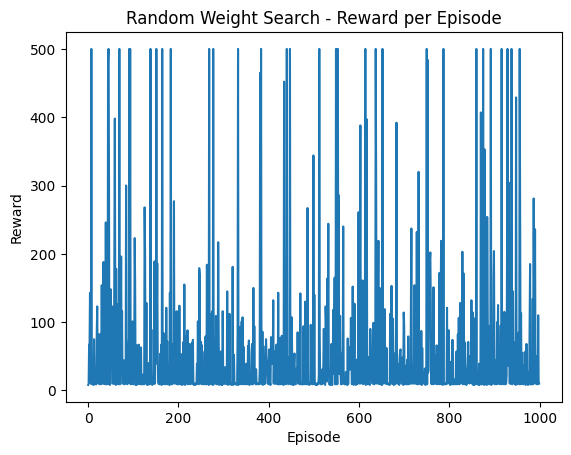

Episode 1: 500.0
Episode 2: 500.0
Episode 3: 500.0
Episode 4: 500.0
Episode 5: 500.0
Episode 6: 500.0
Episode 7: 500.0
Episode 8: 500.0
Episode 9: 500.0
Episode 10: 500.0
Episode 11: 500.0
Episode 12: 500.0
Episode 13: 500.0
Episode 14: 500.0
Episode 15: 500.0
Episode 16: 500.0
Episode 17: 500.0
Episode 18: 500.0
Episode 19: 500.0
Episode 20: 500.0
Episode 21: 500.0
Episode 22: 500.0
Episode 23: 500.0
Episode 24: 433.0
Episode 25: 500.0
Episode 26: 500.0
Episode 27: 500.0
Episode 28: 500.0
Episode 29: 500.0
Episode 30: 500.0
Episode 31: 500.0
Episode 32: 500.0
Episode 33: 500.0
Episode 34: 500.0
Episode 35: 500.0
Episode 36: 500.0
Episode 37: 500.0
Episode 38: 500.0
Episode 39: 500.0
Episode 40: 500.0
Episode 41: 500.0
Episode 42: 500.0
Episode 43: 500.0
Episode 44: 500.0
Episode 45: 500.0
Episode 46: 500.0
Episode 47: 500.0
Episode 48: 500.0
Episode 49: 500.0
Episode 50: 500.0
Episode 51: 500.0
Episode 52: 500.0
Episode 53: 500.0
Episode 54: 500.0
Episode 55: 500.0
Episode 56: 500.0
E

In [2]:
# 导入 Gymnasium 环境库，用于创建和交互 CartPole 环境
import gymnasium as gym
# 导入 PyTorch，用于张量运算和随机权重生成
import torch
# 导入 Matplotlib，用于绘制奖励变化曲线
import matplotlib.pyplot as plt

# 创建 CartPole-v1 环境（最大步数 500，满分 500）
env = gym.make('CartPole-v1')

# 状态维度：CartPole 的观测空间是 4 维向量
# [小车位置, 小车速度, 杆子角度, 杆子角速度]
n_state = env.observation_space.shape[0]  # 4
# 动作数量：离散动作空间，共 2 个动作（0=向左推, 1=向右推）
n_action = env.action_space.n  # 2


def run_episode(env, weight):
    """
    用给定的权重矩阵跑完一个完整的 episode。

    策略：state (4,) × weight (4,2) → 得到 2 维得分向量，
    取 argmax 作为动作（得分最高的那个动作）。
    这本质上是一个线性策略：没有隐藏层，没有激活函数。

    参数:
        env: Gymnasium 环境
        weight: 形状为 (n_state, n_action) 的权重矩阵

    返回:
        该 episode 的累计奖励（即存活步数）
    """
    # 重置环境，获取初始状态和额外信息
    state, info = env.reset()
    total_reward = 0  # 累计奖励
    terminated = False  # 任务是否自然结束（杆倒了 / 车出界）
    truncated = False   # 是否因达到最大步数而截断

    # 只要任务没结束，就持续交互
    while not (terminated or truncated):
        # 将 numpy 数组转为 PyTorch 浮点张量
        state = torch.from_numpy(state).float()
        # 线性映射：state(4,) × weight(4,2) → scores(2,)
        # 取得分最高的动作索引作为本次动作
        action = torch.argmax(torch.matmul(state, weight))
        # 执行动作，获取反馈
        state, reward, terminated, truncated, info = env.step(action.item())
        # 累加奖励（CartPole 每存活一步奖励 +1）
        total_reward += reward

    return total_reward


# ==================== 第一部分：随机搜索 + 评估 ====================

n_episode = 1000  # 随机尝试 1000 组权重

best_total_reward = 0  # 记录历史最佳奖励
best_weight = None     # 记录对应的最佳权重矩阵

total_rewards = []  # 记录每一轮的奖励，用于后续绘图

for episode in range(n_episode):
    # 随机生成一个 (4, 2) 的权重矩阵，元素在 [0, 1) 之间均匀分布
    weight = torch.rand(n_state, n_action)
    # 用这组随机权重跑一个 episode
    total_reward = run_episode(env, weight)
    print(f'Episode {episode + 1}: {total_reward}')

    # 如果这组权重表现更好，就更新最优记录
    if total_reward > best_total_reward:
        best_weight = weight
        best_total_reward = total_reward

    total_rewards.append(total_reward)

# 打印 1000 次随机尝试的平均奖励
print(
    f'Average total reward over {n_episode} episode: '
    f'{sum(total_rewards) / n_episode:.2f}'
)

# 绘制奖励随 episode 变化的曲线
# 由于权重是随机生成的，曲线会上下波动，没有明显的上升趋势
plt.plot(total_rewards)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Random Weight Search - Reward per Episode')
plt.show()


# ==================== 第二部分：用最优权重评估 ====================

n_episode_eval = 100  # 评估回合数
total_rewards_eval = []

for episode in range(n_episode_eval):
    # 用之前找到的 best_weight 跑 episode，不再随机生成
    total_reward = run_episode(env, best_weight)
    print(f'Episode {episode + 1}: {total_reward}')
    total_rewards_eval.append(total_reward)

# 打印评估阶段的平均奖励
print(
    f'Average total reward over {n_episode_eval} eval episode: '
    f'{sum(total_rewards_eval) / n_episode_eval:.2f}'
)


# ==================== 第三部分：早停策略 ====================

n_episode = 1000  # 最多尝试 1000 轮
best_total_reward = 0
best_weight = None
total_rewards = []

for episode in range(n_episode):
    weight = torch.rand(n_state, n_action)
    total_reward = run_episode(env, weight)
    print(f'Episode {episode + 1}: {total_reward}')

    if total_reward > best_total_reward:
        best_weight = weight
        best_total_reward = total_reward

    total_rewards.append(total_reward)

    # CartPole-v1 满分是 500，一旦达到就提前结束搜索
    if best_total_reward == 500:
        print(f'Found perfect weight at episode {episode + 1}!')
        break
    
# 打印最优权重矩阵
print('\n========== 最优权重矩阵 ==========')
print(best_weight)
print(f'最优奖励: {best_total_reward}')
print('================================\n')

# ==================== 第四部分：统计期望训练轮数 ====================

n_training = 1000  # 重复实验 1000 次，求统计期望
n_episode_training = []  # 记录每次实验找到满分权重所需的 episode 数

for _ in range(n_training):
    for episode in range(n_episode):
        weight = torch.rand(n_state, n_action)
        total_reward = run_episode(env, weight)

        # 一旦某组随机权重拿到满分 500，就记录用了多少轮，然后跳出内层循环
        if total_reward == 500:
            n_episode_training.append(episode + 1)
            break

# 打印 1000 次实验的平均值，即"期望需要多少轮随机搜索才能找到满分权重"
print(
    'Expectation of training episodes needed: ',
    sum(n_episode_training) / n_training,
)